In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
import numpy as np

# constants
BATCH_SIZE = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
transform = transforms.ToTensor()

# MNIST setup (doesn't work well since there isn't too much to look at)

In [ ]:
mnist_train = datasets.MNIST(root = './data', train = True, download = True, transform = transform)
mnist_test = datasets.MNIST(root = './data', train = False, download = True, transform = transform)

full_data = torch.cat([mnist_train.data, mnist_test.data], dim = 0)
full_targets = torch.cat([mnist_train.targets, mnist_test.targets], dim=0)

sevens, sevens_labels = full_data[full_targets == 7], full_targets[full_targets == 7]
others, others_labels = full_data[full_targets != 7], full_targets[full_targets != 7]

x_train, y_train = sevens[:(int(len(sevens) * 0.7))], sevens_labels[:(int(len(sevens) * 0.7))]
x_test, y_test = torch.cat([sevens[(int(len(sevens) * 0.7)):], others], dim=0), torch.cat([sevens_labels[(int(len(sevens) * 0.7)):], others_labels], dim=0)

train_dataset = TensorDataset(x_train.unsqueeze(1).float() / 255.0, torch.ones(len(x_train)))
test_dataset  = TensorDataset(x_test.unsqueeze(1).float() / 255.0, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(train_dataset.tensors[0].shape)
print(test_dataset.tensors[0].shape)

torch.Size([5105, 1, 28, 28])
torch.Size([64895, 1, 28, 28])


# Download coco and split

In [2]:
import os
import requests
import zipfile

COCO_DIR = "./data/coco"

os.makedirs(COCO_DIR, exist_ok=True)

urls = {
    "train_images": (
        "http://images.cocodataset.org/zips/train2017.zip",
        os.path.join(COCO_DIR, "train2017.zip"),
    ),
    "val_images": (
        "http://images.cocodataset.org/zips/val2017.zip",
        os.path.join(COCO_DIR, "val2017.zip"),
    ),
    "annotations": (
        "http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
        os.path.join(COCO_DIR, "annotations_trainval2017.zip"),
    ),
}

def download_file(url, destination):
    if os.path.exists(destination):
        print(f"Already exists: {destination}")
        return

    print(f"Downloading: {url}")
    response = requests.get(url, stream=True)
    total = int(response.headers.get("content-length", 0))

    with open(destination, "wb") as file, tqdm(
        desc=destination,
        total=total,
        unit='iB',
        unit_scale=True,
        unit_divisor=1024,
    ) as bar:
        for data in response.iter_content(chunk_size=1024):
            size = file.write(data)
            bar.update(size)

for name, (url, dest) in urls.items():
    download_file(url, dest)

def extract_zip(path, extract_to):
    print(f"Extracting {path} ...")
    with zipfile.ZipFile(path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)

extract_zip(urls["train_images"][1], COCO_DIR)
extract_zip(urls["val_images"][1], COCO_DIR)
extract_zip(urls["annotations"][1], COCO_DIR)

print("COCO download complete!")

Already exists: ./data/coco/train2017.zip
Already exists: ./data/coco/val2017.zip
Already exists: ./data/coco/annotations_trainval2017.zip
Extracting ./data/coco/train2017.zip ...
Extracting ./data/coco/val2017.zip ...
Extracting ./data/coco/annotations_trainval2017.zip ...
COCO download complete!


In [2]:
# Assumes the COCO set is setup
import os
from PIL import Image
from pycocotools.coco import COCO

COCO_DIR = "./data/coco"
ANN_FILE  = f"{COCO_DIR}/annotations/instances_train2017.json"
IMG_DIR   = f"{COCO_DIR}/train2017"

TARGET_CLASS = "train"

coco = COCO(ANN_FILE)

cat_ids = coco.getCatIds(catNms=[TARGET_CLASS])
cat_id = cat_ids[0]
print("Using category:", coco.loadCats(cat_id)[0])

normal_img_ids = coco.getImgIds(catIds=[cat_id])
all_img_ids = coco.getImgIds()
other_img_ids = list(set(all_img_ids) - set(normal_img_ids))

print(f"Normal class images: {len(normal_img_ids)}")
print(f"Other class images: {len(other_img_ids)}, (will be reduced for ease)")

normal_img_ids = np.array(normal_img_ids)
np.random.shuffle(normal_img_ids)

split_idx = int(0.7 * len(normal_img_ids))
train_ids = normal_img_ids[:split_idx]
test_normal_ids = normal_img_ids[split_idx:]
other_img_ids = other_img_ids[:len(test_normal_ids) + 2500] # otherwise ts would take way too long

test_ids = list(test_normal_ids) + other_img_ids

raw_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()  # [0,1]
])

def load_coco_tensors(coco, img_ids, img_dir, transform):
  tensors = []
  labels = []

  for img_id in tqdm(img_ids, desc="Loading images"):
    infos = coco.loadImgs(int(img_id))
    if len(infos) == 0:
      continue

    info = infos[0]
    img_path = os.path.join(img_dir, info["file_name"])

    if not os.path.exists(img_path):
      continue

    img = Image.open(img_path).convert("RGB")
    t = transform(img)

    tensors.append(t)
    labels.append(img_id)

  return torch.stack(tensors), torch.tensor(labels)


print("Loading TRAIN images...")
x_train, y_train_raw = load_coco_tensors(
  coco=coco,
  img_ids=train_ids,
  img_dir=IMG_DIR,
  transform=raw_transform
)

print("Loading TEST images...")
x_test, y_test_raw = load_coco_tensors(
  coco=coco,
  img_ids=test_ids,
  img_dir=IMG_DIR,
  transform=raw_transform
)

y_test = torch.tensor([1 if img_id in test_normal_ids else 0 for img_id in test_ids]) # 1 = normal 0 = anomaly

train_dataset = TensorDataset(x_train, torch.ones(len(x_train)))
test_dataset  = TensorDataset(x_test,  y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(train_dataset.tensors[0].shape)
print(test_dataset.tensors[0].shape)

loading annotations into memory...
Done (t=14.57s)
creating index...
index created!
Using category: {'supercategory': 'vehicle', 'id': 7, 'name': 'train'}
Normal class images: 3588
Other class images: 114699, (will be reduced for ease)
Loading TRAIN images...


Loading images: 100%|██████████| 2511/2511 [00:21<00:00, 116.53it/s]


Loading TEST images...


Loading images: 100%|██████████| 4654/4654 [00:37<00:00, 123.62it/s]


torch.Size([2511, 3, 256, 256])
torch.Size([4654, 3, 256, 256])


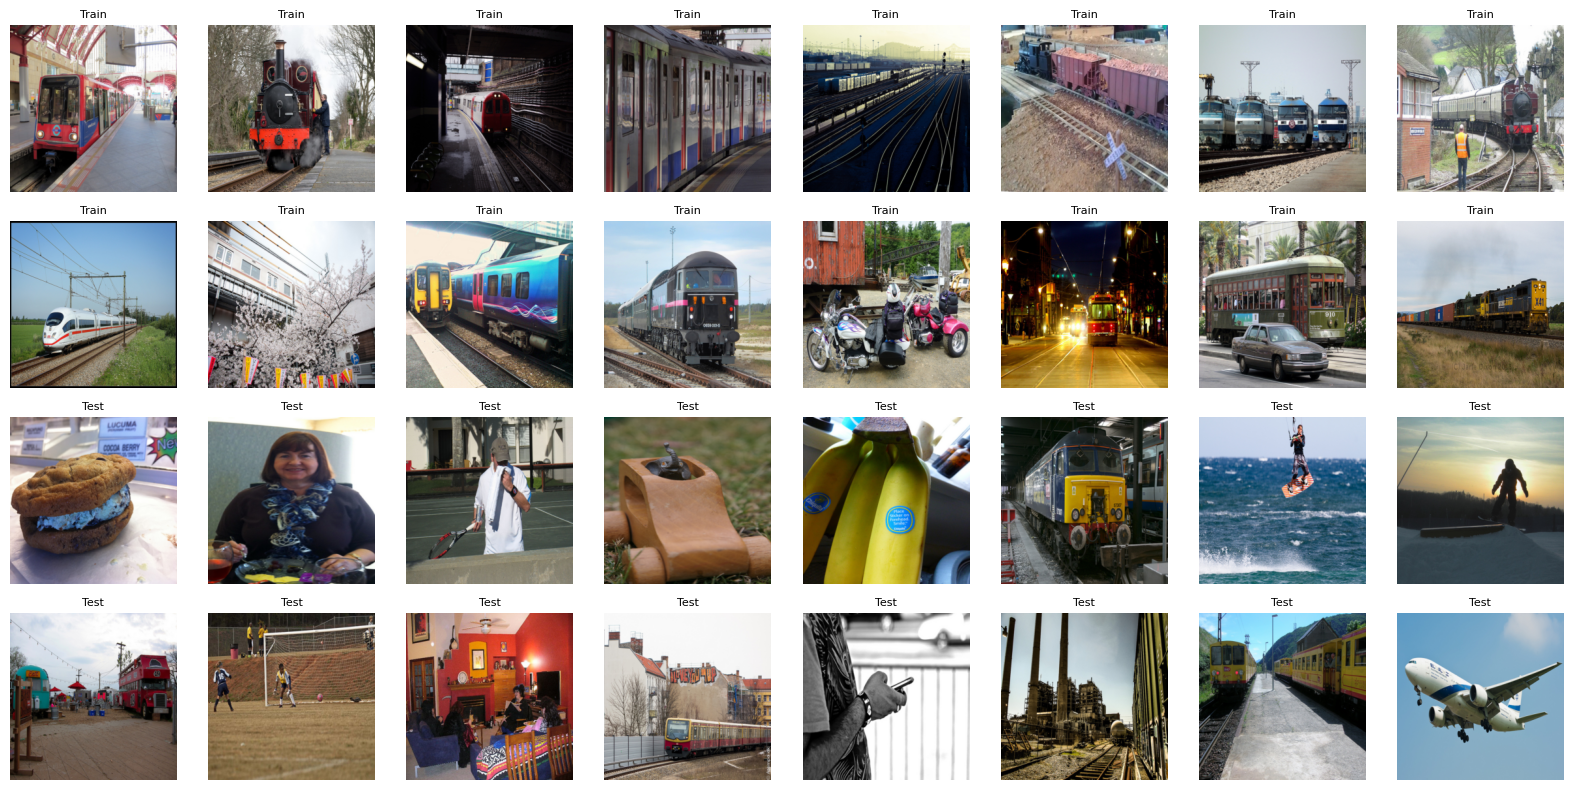

In [3]:
import matplotlib.pyplot as plt
import torch
import numpy as np

num_images_per_set = 16
rows, cols = 4, 8
plt.figure(figsize=(16, 8))

train_indices = torch.randperm(len(train_dataset))[:num_images_per_set]
test_indices  = torch.randperm(len(test_dataset))[:num_images_per_set]

train_imgs = [train_dataset[i][0] for i in train_indices]
test_imgs  = [test_dataset[i][0] for i in test_indices]

all_imgs = train_imgs + test_imgs

for i, img in enumerate(all_imgs):
  if isinstance(img, torch.Tensor):
    img = img.cpu().numpy()

  img = np.transpose(img, (1, 2, 0))

  plt.subplot(rows, cols, i + 1)
  plt.imshow(img)
  plt.axis('off')

  if i < num_images_per_set:
    plt.title("Train", fontsize=8)
  else:
    plt.title("Test", fontsize=8)

plt.tight_layout()
plt.show()

In [4]:
!pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-47chz0_v
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-47chz0_v
  Resolved https://github.com/openai/CLIP.git to commit dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1
  Preparing metadata (setup.py) ... done


# Setup model + train

In [5]:
import clip

device = "cuda" if torch.cuda.is_available() else "cpu"

model, preprocess = clip.load("ViT-B/32", device=device)
model.eval()

CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (transformer): Transformer(
      (resblocks): Sequential(
        (0): ResidualAttentionBlock(
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): QuickGELU()
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        )
        (1): ResidualAttentionBlock(
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          

In [6]:
all_features = []

with torch.no_grad():
  for batch_images, _ in tqdm(train_loader, desc="Extracting CLIP features"):
    processed_images = []

    for img in batch_images:
      pil_img = transforms.ToPILImage()(img)
      processed_images.append(preprocess(pil_img))

    processed_images = torch.stack(processed_images).to(device)

    features = model.encode_image(processed_images)
    features = features / features.norm(dim=-1, keepdim=True)

    all_features.append(features.cpu())

all_features = torch.cat(all_features, dim=0).numpy()

Extracting CLIP features: 100%|██████████| 79/79 [00:14<00:00,  5.54it/s]


# SVM

In [7]:
from sklearn.svm import OneClassSVM

clf = OneClassSVM(gamma='auto', nu=0.05)
clf.fit(all_features)

predictions = clf.predict(all_features)

In [8]:
import joblib

joblib.dump(clf, f"model_svm_{TARGET_CLASS}.clk")

['model_svm_train.clk']

# Deep SVDD

In [9]:
import torch.nn as nn
import torch.functional as F
import torch.optim as optim

class DeepSVDD(nn.Module):
  def __init__(self, input_dim = 512, hidden_dim = 256, output_dim = 128):
    super(DeepSVDD, self).__init__()
    self.net = nn.Sequential(
        nn.Linear(input_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, output_dim)
    )
  def forward(self, x):
    return self.net(x)

svdd_head = DeepSVDD(input_dim=features.shape[1]).to(device)

In [10]:
optimizer = optim.Adam(svdd_head.parameters(), lr=0.001)
EPOCHS = 100

features = torch.from_numpy(all_features).float()

with torch.no_grad():
    c = svdd_head(features.to(device)).mean(dim=0)

dataset = torch.utils.data.TensorDataset(features)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

for epoch in range(EPOCHS):
  epoch_loss = 0.0
  for batch in loader:
    x_batch = batch[0].to(device)
    z = svdd_head(x_batch)
    loss = torch.mean(torch.sum((z - c)**2, dim=1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    epoch_loss += loss.item() * x_batch.size(0)
  if epoch % 10 == 0:
    print(f"Epoch {epoch+1}/{EPOCHS}, Loss: {epoch_loss / len(dataset):.6f}")

with torch.no_grad():
  svdd_embeddings = svdd_head(features.to(device))
  distances = torch.norm(svdd_embeddings - c, dim=1)

Epoch 1/100, Loss: 0.000864
Epoch 11/100, Loss: 0.000007
Epoch 21/100, Loss: 0.000002
Epoch 31/100, Loss: 0.000002
Epoch 41/100, Loss: 0.000002
Epoch 51/100, Loss: 0.000001
Epoch 61/100, Loss: 0.000001
Epoch 71/100, Loss: 0.000001
Epoch 81/100, Loss: 0.000000
Epoch 91/100, Loss: 0.000000


In [11]:
import joblib

joblib.dump(svdd_head, f"model_svdd_{TARGET_CLASS}.clk")

['model_svdd_train.clk']

# Results

In [12]:
all_test_features = []
all_test_labels = []

with torch.no_grad():
  for batch_images, batch_labels in tqdm(test_loader, desc="Extracting CLIP features"):
    processed_images = []
    for img in batch_images:
      pil_img = transforms.ToPILImage()(img)
      processed_images.append(preprocess(pil_img))
    processed_images = torch.stack(processed_images).to(device)
    features = model.encode_image(processed_images)
    features = features / features.norm(dim=-1, keepdim=True)
    all_test_features.append(features.cpu())
    all_test_labels.append(batch_labels)

all_test_features = torch.cat(all_test_features, dim=0).numpy()
all_test_labels = torch.cat(all_test_labels, dim=0).numpy()

Extracting CLIP features: 100%|██████████| 146/146 [00:18<00:00,  7.80it/s]


# SVM

In [13]:
predictions = clf.predict(all_test_features)

In [14]:
y_true = np.where(all_test_labels == 1, 1, -1)
y_pred = predictions

accuracy = (y_pred == y_true).mean()
print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 82.08%


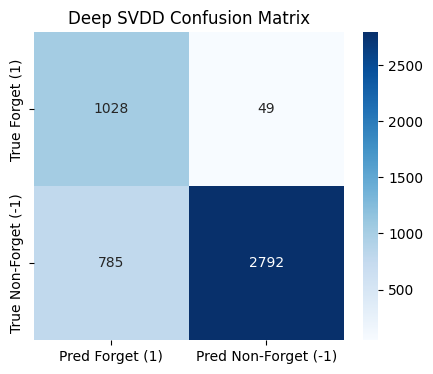

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred, labels=[1, -1])
df_cm = pd.DataFrame(
    cm,
    index=["True Forget (1)", "True Non-Forget (-1)"],
    columns=["Pred Forget (1)", "Pred Non-Forget (-1)"]
)

plt.figure(figsize=(5,4))
sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Deep SVDD Confusion Matrix")
plt.show()

# SVDD

In [16]:
test_features = torch.from_numpy(all_test_features).float().to(device)
test_labels = torch.from_numpy(all_test_labels).long()

with torch.no_grad():
    svdd_test_embeddings = svdd_head(test_features)
    test_distances = torch.norm(svdd_test_embeddings - c, dim=1).cpu().numpy()

In [17]:
threshold = torch.quantile(distances, 0.999).item()
y_pred = np.where(test_distances <= threshold, 1, -1)
y_true = np.where(all_test_labels == 1, 1, -1)

acc = (y_pred == y_true).mean()
print(f"Accuracy: {acc*100:.2f}%")

Accuracy: 93.58%


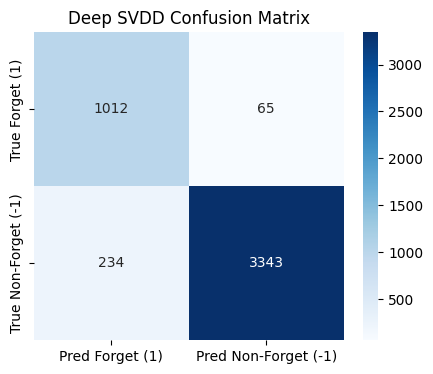

In [18]:
cm = confusion_matrix(y_true, y_pred, labels=[1, -1])
df_cm = pd.DataFrame(
    cm,
    index=["True Forget (1)", "True Non-Forget (-1)"],
    columns=["Pred Forget (1)", "Pred Non-Forget (-1)"]
)

plt.figure(figsize=(5,4))
sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Deep SVDD Confusion Matrix")
plt.show()